# Project 1: Student Performance Prediction System 

In [1]:
# 1 — Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

In [2]:
# 2 — Create Dataset
data = {
    "Attendance": [85,90,75,95,60,80,88,70,92,65,78,84,91,73,87,68,96,82,76,89],
    "Internal_Marks": [78,85,65,90,55,72,82,60,88,58,70,76,84,63,80,57,92,75,68,86],
    "Assignment_Marks": [80,88,70,92,50,75,85,65,90,55,72,78,86,68,82,60,95,80,70,89],
    "Study_Hours": [4,5,3,6,2,4,5,2,6,2,3,4,5,3,5,2,7,4,3,6],
    "Previous_Semester": [75,82,68,88,52,70,80,58,85,50,67,73,81,60,78,55,90,72,65,84],
    "Final_Marks": [78,85,68,91,52,73,83,61,88,54,70,76,84,64,81,58,94,76,68,87]
}

df = pd.DataFrame(data)

print(df.head())
print("\nMissing Values:")
print(df.isnull().sum())

   Attendance  Internal_Marks  Assignment_Marks  Study_Hours  \
0          85              78                80            4   
1          90              85                88            5   
2          75              65                70            3   
3          95              90                92            6   
4          60              55                50            2   

   Previous_Semester  Final_Marks  
0                 75           78  
1                 82           85  
2                 68           68  
3                 88           91  
4                 52           52  

Missing Values:
Attendance           0
Internal_Marks       0
Assignment_Marks     0
Study_Hours          0
Previous_Semester    0
Final_Marks          0
dtype: int64


In [3]:
# 3 — Prepare Data & Split
X = df[["Attendance", "Internal_Marks", "Assignment_Marks",
        "Study_Hours", "Previous_Semester"]]

y = df["Final_Marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (16, 5)
Testing: (4, 5)


In [4]:
# 4 — Train Model & Predict
model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Predicted Marks:")
print(y_pred)

Predicted Marks:
[77.92036555 75.9733018  57.56273301 85.37262539]


In [5]:
# 5 — Evaluate Model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE : 0.22905626058958006
MSE : 0.08427663654761205
RMSE: 0.2903043860288922
R2 Score: 0.9991503300663127


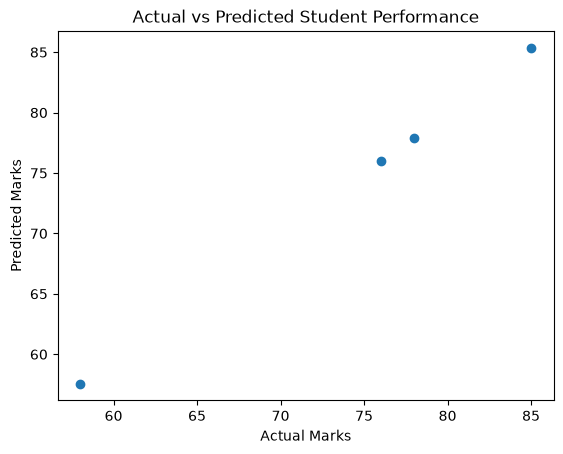

In [6]:
# 6 — Actual vs Predicted Graph
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Student Performance")

plt.show()

In [7]:
# 7 — New Student Prediction + Save Model
new_student = pd.DataFrame({
    "Attendance": [90],
    "Internal_Marks": [85],
    "Assignment_Marks": [88],
    "Study_Hours": [5],
    "Previous_Semester": [82]
})

prediction = model.predict(new_student)

print("Predicted Final Marks:", prediction[0])

joblib.dump(model, "student_performance_model.pkl")
print("Model saved successfully.")

Predicted Final Marks: 85.37262539473048
Model saved successfully.


# Project 2: House Price Prediction System 

In [8]:
# 1 — Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

In [9]:
# 2 — Create Dataset
data = {
    "Area": [1200, 1500, 900, 1800, 1100, 2000, 1400, 1000, 1600, 1300,
             2200, 950, 1700, 1250, 1900, 1050, 1450, 1550, 1150, 2100],

    "Bedrooms": [2, 3, 2, 4, 2, 4, 3, 2, 3, 3,
                 4, 2, 3, 2, 4, 2, 3, 3, 2, 4],

    "Location": ["Delhi", "Noida", "Delhi", "Noida", "Ghaziabad",
                 "Noida", "Delhi", "Ghaziabad", "Noida", "Delhi",
                 "Noida", "Ghaziabad", "Delhi", "Noida", "Delhi",
                 "Ghaziabad", "Noida", "Delhi", "Ghaziabad", "Noida"],

    "Bathrooms": [2, 2, 1, 3, 2, 3, 2, 1, 2, 2,
                  3, 1, 2, 2, 3, 1, 2, 2, 1, 3],

    "Parking": [1, 1, 0, 2, 1, 2, 1, 0, 1, 1,
                2, 0, 1, 1, 2, 0, 1, 1, 0, 2],

    "Age": [5, 3, 10, 2, 8, 1, 6, 12, 4, 7,
            2, 15, 5, 9, 3, 14, 6, 4, 11, 2],

    "Price": [55, 72, 42, 95, 50, 110, 68, 40, 78, 60,
              125, 38, 85, 52, 105, 43, 70, 76, 45, 115]
}

df = pd.DataFrame(data)

print(df.head())
print("\nMissing Values:")
print(df.isnull().sum())

   Area  Bedrooms   Location  Bathrooms  Parking  Age  Price
0  1200         2      Delhi          2        1    5     55
1  1500         3      Noida          2        1    3     72
2   900         2      Delhi          1        0   10     42
3  1800         4      Noida          3        2    2     95
4  1100         2  Ghaziabad          2        1    8     50

Missing Values:
Area         0
Bedrooms     0
Location     0
Bathrooms    0
Parking      0
Age          0
Price        0
dtype: int64


In [10]:
# 3 — Preprocessing
df = pd.get_dummies(df, columns=["Location"], dtype=int)

X = df.drop("Price", axis=1)
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16, 8)
Testing data: (4, 8)


In [11]:
# 4 — Train Two Regression Models
linear_model = LinearRegression()
forest_model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

linear_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)
forest_pred = forest_model.predict(X_test)

print("Both models trained successfully.")

Both models trained successfully.


In [12]:
# 5 — Compare Model Performance
def evaluate(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    print("\n", name)
    print("MAE :", mae)
    print("MSE :", mse)
    print("RMSE:", rmse)
    print("R2  :", r2)

evaluate("Linear Regression", y_test, linear_pred)
evaluate("Random Forest", y_test, forest_pred)


 Linear Regression
MAE : 1.4246349752211636
MSE : 2.7115695249194576
RMSE: 1.6466844035574812
R2  : 0.9846152083692513

 Random Forest
MAE : 4.6899999999999995
MSE : 29.70475000000001
RMSE: 5.450206418109319
R2  : 0.8314624113475176


   Actual Price  Linear Regression  Random Forest
0            55          53.835734          64.01
1            76          78.542926          77.74
2            43          42.725976          40.12
3            72          73.717323          77.13


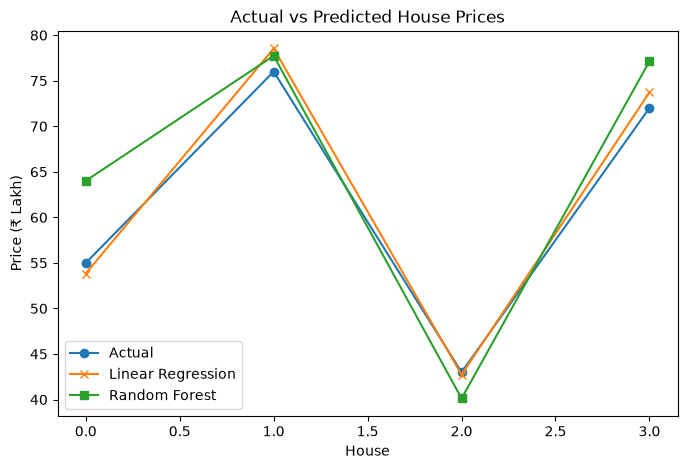

In [13]:
# 6 — Actual vs Predicted
result = pd.DataFrame({
    "Actual Price": y_test.values,
    "Linear Regression": linear_pred,
    "Random Forest": forest_pred
})

print(result)

plt.figure(figsize=(8, 5))
plt.plot(result["Actual Price"].values, marker="o", label="Actual")
plt.plot(result["Linear Regression"].values, marker="x", label="Linear Regression")
plt.plot(result["Random Forest"].values, marker="s", label="Random Forest")

plt.xlabel("House")
plt.ylabel("Price (₹ Lakh)")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.show()

In [14]:
# 7 — New House Prediction + Save Best Model
new_house = pd.DataFrame({
    "Area": [1500],
    "Bedrooms": [3],
    "Bathrooms": [2],
    "Parking": [1],
    "Age": [5],
    "Location_Delhi": [0],
    "Location_Ghaziabad": [0],
    "Location_Noida": [1]
})

prediction = forest_model.predict(new_house)

print("Predicted House Price: ₹", prediction[0], "Lakh")

joblib.dump(forest_model, "house_price_model.pkl")
print("Model saved successfully.")

Predicted House Price: ₹ 75.12 Lakh
Model saved successfully.
